# Module 4 · Agentic RAG in LangGraph

Module 3 searches, but trusts whatever comes back. Module 4 gives retrieval judgment: **route** (search or not),
**retrieve**, **grade** the chunks, **rewrite** and retry when they are weak, and **verify** the
answer. Every loop is bounded by a counter in state.

Then the demo, four questions that exercise every branch:
"Hi!" → no retrieval · "Q3 margin?" → 1 search · "Q3 vs Q2, and why?" → 2 searches + grade ·
a vague question → rewrite + retry. Then the same three-question conversation as Modules 1 and 2,
on one thread, with its cost charted against both.

The graph built here is `build_v3_graph` in `agents/agentic_rag.py`, which Module 5 serves on
AgentShip unchanged.

**Setup:** see `README.md` (`pip install -e .`, then `.env` names the model and server). Run with the *Agentic RAG demos* kernel.

In [1]:
import json
import re
import time

import httpx
from langchain.chat_models import init_chat_model
from langchain_core.callbacks import get_usage_metadata_callback
from langchain_core.messages import AIMessage, HumanMessage, RemoveMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

from tools.charts import compare, load_runs, save_runs
from tools.search_docs import format_hits, load_collection
from tools.search_docs import search_docs as search_index # a query to Module 2's Chroma collection
from tools.settings import API_BASE, CHAT_KWARGS, CHAT_MODEL, DETERMINISTIC, HEADERS, RERANK_MODEL, price

collection = load_collection() # the cached vectors from Module 2, in an in-memory Chroma collection
model = init_chat_model(CHAT_MODEL, **CHAT_KWARGS)
print(f"Model: {CHAT_MODEL} Grader: {RERANK_MODEL or CHAT_MODEL} Index: {collection.count()} chunks in Chroma")

Model: litellm:gemini/gemini-3.5-flash Grader: litellm:gemini/gemini-3.5-flash Index: 240 chunks in Chroma


## RAG is just another tool

The description **is** the routing policy: what the documents hold, and when *not* to search.
Behind the tool is Module 2's index: `search_index` embeds the query and asks the Chroma collection for the nearest chunks.

In [2]:
@tool
def search_docs(query: str, k: int = 5) -> str:
    """Search Acme's internal filings (the Q3 2026 10-Q, with Q2 2026 results in an appendix).
    Use for Acme-specific numbers. One quarter or topic per search: to compare two quarters,
    call it once for each. Do NOT use for definitions, small talk or live prices."""
    return format_hits(search_index(query, k))


@tool
def web_search(query: str) -> str:
    """Search the live web, for news and prices that change daily."""
    return "web_search is not connected in this lab."

### Call RAG or not? Let the LLM decide

Bind both tools and look only at the model's decision. Nothing is searched yet.

In [3]:
router = model.bind_tools([search_docs, web_search])
for q in ["Thanks, that helps!", "What is a P/E ratio?", "What was our Q3 revenue?",
          "Compare Q3 vs Q2 margins", "Today's Acme stock price?"]:
    calls = router.invoke(q).tool_calls
    decision = ", ".join(f"{c['name']}({c['args'].get('query', '')!r})" for c in calls) or "answer directly"
    print(f"{q:<28} → {decision}")

Thanks, that helps!          → answer directly


What is a P/E ratio?         → answer directly


What was our Q3 revenue?     → search_docs('Q3 revenue')


Compare Q3 vs Q2 margins     → search_docs('Q3 2026 margin profit gross operating'), search_docs('Q2 2026 margin profit gross operating')


Today's Acme stock price?    → web_search('Acme stock price today')


## The graph: route, retrieve, grade, retry, verify

The state is `MessagesState` plus counters. `retries` is what makes the loop end.

In [4]:
PROMPT = """You answer questions about Acme Corp's quarterly filing (Form 10-Q for Q3 2026).
Use search_docs for any Acme-specific fact or number, once per quarter or topic you need: to
compare two quarters, search for each. Answer greetings, thanks and general definitions directly,
without searching. Answer only from the search results, cite chunk ids like [chunk 36], and say
so when the filings don't contain the answer. Be concise."""

MAX_RETRIES = 2 # rewrites per question
MAX_SEARCHES = 4 # search rounds per question, a second cap so the loop always ends
SEPARATOR = "\n\n---\n\n" # between chunks in a search_docs result


class RAGState(MessagesState):
    retries: int # rewrites so far this question: the counter that ends the loop
    relevant: int # chunks the grader kept from the last search
    note: str | None # a one-off instruction for the agent's next call, from verify
    query: str | None # the rewritten query the agent must search with next
    verified: bool

In [5]:
def _text(message) -> str:
    return message.content if isinstance(message.content, str) else str(message.content)


def _this_turn(messages: list) -> list:
    """Everything from the latest user message on."""
    start = max(i for i, m in enumerate(messages) if isinstance(m, HumanMessage))
    return messages[start:]

In [6]:
tools = [search_docs]
llm = model.bind_tools(tools)
judge = model.bind(**DETERMINISTIC) # the small decisions should not be a coin toss


def ask(prompt: str) -> str: # the small decisions: grade, rewrite, verify
    return _text(judge.invoke([HumanMessage(content=prompt)])).strip()

**The grader** · a small model scores each chunk against the query that found it. A cross-encoder reranker reads the pair together; above 0 means relevant.

In [7]:
def relevant(query: str, passages: list[str], ask) -> list[bool]:
    """The grader: which passages state what the search looked for?

    A cross-encoder (DEMO_RERANK_MODEL) reads each query–passage pair and scores it: above 0 means
    relevant. It is small, fast and steadier than asking the chat model. Without one, the chat model
    picks the passages instead.
    """
    if RERANK_MODEL:
        resp = httpx.post(f"{API_BASE}/reranking", headers=HEADERS, timeout=60,
                          json={"model": RERANK_MODEL, "query": query, "documents": passages})
        resp.raise_for_status()
        scores = {r["index"]: r["relevance_score"] for r in resp.json()["results"]}
        return [scores[i] > 0 for i in range(len(passages))]
    listing = "\n\n".join(f"<passage {n}>\n{p}\n</passage {n}>" for n, p in enumerate(passages, 1))
    verdict = ask(f"Search: {query}\n\n{listing}\n\nWhich passages state what the search looks for? "
                  f'Reply with JSON only, like {{"relevant": [1, 3]}}, or {{"relevant": []}}.')
    try:
        keep = {int(n) for n in json.loads(re.search(r"\{.*\}", verdict, re.S).group())["relevant"]}
    except Exception: # an unreadable verdict: keep everything rather than lose evidence
        keep = set(range(1, len(passages) + 1))
    return [n in keep for n in range(1, len(passages) + 1)]

**agent** · the LLM with `search_docs` bound. A new question resets the counters. After `MAX_SEARCHES` rounds it gets no tools, so the loop has to end.

In [8]:
def agent(state: RAGState) -> dict:
    """LLM + search_docs: decides whether to search, what for, and when to answer."""
    messages = state["messages"]
    new_turn = isinstance(messages[-1], HumanMessage)
    note = None if new_turn else state.get("note")
    searches = sum(1 for m in _this_turn(messages) if isinstance(m, AIMessage) and m.tool_calls)
    system = PROMPT + (f"\n\n{note}" if note else "")
    history = [m for m in messages if not isinstance(m, SystemMessage)]
    if state.get("query") and not new_turn and searches < MAX_SEARCHES: # after a rewrite
        call = {"name": "search_docs", "args": {"query": state["query"]}, "id": f"rewrite-{state['retries']}"}
        reply = AIMessage(content="", tool_calls=[call])
    elif searches < MAX_SEARCHES:
        reply = llm.invoke([SystemMessage(content=system)] + history)
    else: # out of searches: hand over the results as plain text, with no tools and no tool calls in sight
        turn = _this_turn(history)
        earlier = [m for m in history[:len(history) - len(turn)] # past questions and final answers only
                   if isinstance(m, HumanMessage) or (isinstance(m, AIMessage) and not m.tool_calls)]
        results = SEPARATOR.join(_text(m) for m in turn if isinstance(m, ToolMessage))
        system += "\n\nYou have used every search for this question. Answer from the search results given."
        ask_once = HumanMessage(content=f"{_text(turn[0])}\n\nSearch results:\n\n{results}")
        reply = model.invoke([SystemMessage(content=system)] + earlier + [ask_once])
        if reply.tool_calls or "<tool_call>" in _text(reply): # a search anyway, as a call or as text
            answer = _text(reply).split("<tool_call>")[0].strip()
            reply = AIMessage(content=answer or "The filings' search results don't answer this.")
    update = {"messages": [reply], "note": None, "query": None}
    if new_turn:
        update |= {"retries": 0, "relevant": 0, "verified": False}
    return update

**grade** · one call to the model: which chunks help? The rest are dropped from the context.

In [9]:
def grade(state: RAGState) -> dict:
    """Small model: which chunks state what each search looked for? Drop the rest."""
    messages = state["messages"]
    results = []
    for m in reversed(messages): # the ToolMessages this search just added
        if not isinstance(m, ToolMessage):
            break
        results.insert(0, m)
    call = next(m for m in reversed(messages) if isinstance(m, AIMessage) and m.tool_calls)
    queries = {c["id"]: c["args"].get("query", "") for c in call.tool_calls}
    graded, n_relevant = [], 0
    for m in results: # each search is graded against its own query
        passages = [p for p in _text(m).split(SEPARATOR) if p.strip()]
        kept = [p for p, ok in zip(passages, relevant(queries.get(m.tool_call_id, ""), passages, ask)) if ok]
        n_relevant += len(kept)
        graded.append(ToolMessage(content=SEPARATOR.join(kept) or "No relevant passages.",
                                  tool_call_id=m.tool_call_id, name=m.name, id=m.id))
    return {"messages": graded, "relevant": n_relevant}

**rewrite** · nothing relevant: write a better query, and add one to `retries`.

In [10]:
def rewrite(state: RAGState) -> dict:
    """Nothing relevant: write a better query, count one retry."""
    messages = state["messages"]
    question = _text(_this_turn(messages)[0])
    last = next(m for m in reversed(messages) if isinstance(m, AIMessage) and m.tool_calls)
    queries = [c["args"].get("query", "") for c in last.tool_calls]
    better = ask(f"Question: {question}\nThese searches of a company's 10-Q filing found nothing "
                 f"relevant: {queries}\nWrite one better search query, in the words a 10-Q would "
                 f"use. Reply with the query only.").splitlines()[0][:200]
    return {"retries": state.get("retries", 0) + 1, "query": better}

**give_up** · out of retries: say so instead of guessing.

In [11]:
def give_up(state: RAGState) -> dict:
    """Out of retries: say so instead of guessing."""
    return {"messages": [AIMessage(content="I couldn't find that in Acme's filings, even after "
                                           "rewriting the search.")]}

**verify** · is every claim in the answer in the evidence? If not, answer once more.

In [12]:
def check(state: RAGState) -> dict:
    """Verify: is every claim in the answer in the evidence? If not, answer once more."""
    messages = state["messages"]
    evidence = "\n\n".join(_text(m) for m in _this_turn(messages) if isinstance(m, ToolMessage))
    if state.get("verified") or not evidence: # already checked, or nothing was searched
        return {}
    answer = messages[-1]
    verdict = ask(f"EVIDENCE:\n{evidence}\n\nANSWER:\n{_text(answer)}\n\nIs every number and factual "
                  f"claim in ANSWER supported by EVIDENCE? Saying the evidence doesn't contain something counts as "
                  f"supported. Reply with yes or no only.")
    if verdict.strip("*_ .").lower().startswith("yes"):
        return {"verified": True}
    return {"verified": True, "messages": [RemoveMessage(id=answer.id)],
            "note": "Your last answer had claims that are not in the search results. Answer again "
                    "using only the search results, or say the filings don't contain it."}

**The decision after grading**.

In [13]:
def after_grade(state: RAGState) -> str:
    if state["relevant"]:
        return "agent" # good: answer
    if state.get("retries", 0) < MAX_RETRIES:
        return "rewrite" # weak: try again
    return "give_up" # out of retries

### Wire it up

Same building blocks as Module 3: nodes, a router, and edges back. `tools_condition` routes
after the agent, exactly as in Module 3; `after_grade` answers, retries, or gives up.

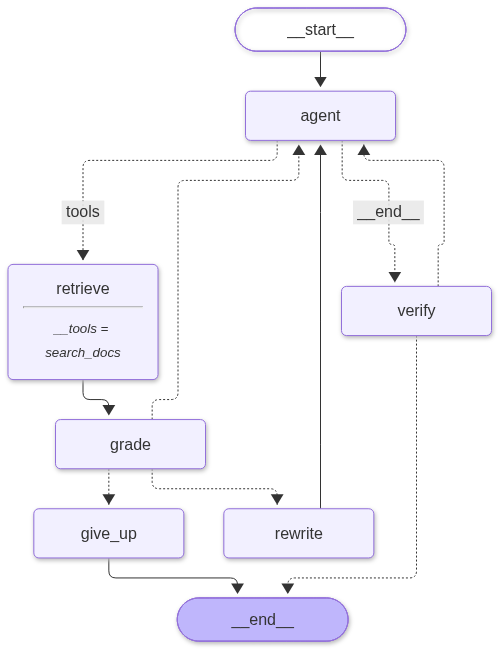

In [14]:
verify = True

g = StateGraph(RAGState)
g.add_node("agent", agent) # LLM + search_docs
g.add_node("retrieve", ToolNode(tools))
g.add_node("grade", grade) # small model: relevant?
g.add_node("rewrite", rewrite) # better query, retries+1
g.add_node("give_up", give_up)
g.add_edge(START, "agent")
g.add_conditional_edges("agent", tools_condition, {"tools": "retrieve", END: "verify" if verify else END})
g.add_edge("retrieve", "grade")
g.add_conditional_edges("grade", after_grade, ["agent", "rewrite", "give_up"])
g.add_edge("rewrite", "agent")
g.add_edge("give_up", END)
if verify: # the last step, before the final answer
    g.add_node("verify", check)
    g.add_conditional_edges("verify", lambda s: "agent" if s.get("note") else END, ["agent", END])

app = g.compile(checkpointer=InMemorySaver())
from IPython.display import Image, display

try: # the graph as a picture, drawn by mermaid.ink
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception: # offline: the Mermaid source, to paste into https://mermaid.live
    print(app.get_graph().draw_mermaid())

## Demo

Stream each run with `stream_mode="updates"` to see which path it took.

In [15]:
from uuid import uuid4

runs = [] # tokens and cost per question, for the charts at the end


def run(question: str, thread: str | None = None) -> None:
    """One question, on a new thread unless you pass one, so each demo starts clean."""
    print(f"› {question}\n")
    cfg = {"configurable": {"thread_id": thread or str(uuid4())}, "recursion_limit": 25}
    start = time.perf_counter()
    with get_usage_metadata_callback() as usage: # adds up every model call: agent, grade, rewrite, verify
        _stream(question, cfg)
    latency = time.perf_counter() - start
    tokens_in = sum(u["input_tokens"] for u in usage.usage_metadata.values())
    tokens_out = sum(u["output_tokens"] for u in usage.usage_metadata.values())
    cost = price(tokens_in, tokens_out)
    runs.append({"question": question, "prompt_tokens": tokens_in, "completion_tokens": tokens_out,
                 "latency_s": round(latency, 2), "cost_usd": cost})
    print(f"\nprompt_tokens={tokens_in:,} completion_tokens={tokens_out:,} "
          f"latency={latency:.2f}s cost={'$%.4f' % cost if cost is not None else 'n/a'}\n")


def _stream(question: str, cfg: dict) -> None:
    """Print which node ran and what it did, as the graph runs."""
    for step in app.stream({"messages": [("user", question)]}, cfg, stream_mode="updates"):
        for node, update in step.items():
            update = update or {}
            for m in update.get("messages", []):
                if isinstance(m, RemoveMessage):
                    print(f" {node:>8} → unsupported claims: answer again")
                elif getattr(m, "tool_calls", None):
                    print(f" {node:>8} → search_docs{[c['args']['query'] for c in m.tool_calls]}")
                elif isinstance(m, ToolMessage) and node == "retrieve":
                    print(f" {node:>8} → {m.content.count('[chunk ')} chunks")
                elif not isinstance(m, ToolMessage):
                    print(f" {node:>8} → {m.content}")
            if node == "grade":
                print(f" {node:>8} → {update['relevant']} relevant chunks kept")
            if node == "rewrite":
                print(f" {node:>8} → retry {update['retries']}: {update['query']!r}")
            if node == "verify" and update.get("verified") and not update.get("messages"):
                print(f" {node:>8} → every claim is in the evidence")

In [16]:
run("Hi!")

› Hi!



    agent → Hello! How can I help you with Acme Corp's Q3 2026 Form 10-Q filing today?

prompt_tokens=230 completion_tokens=28 latency=1.05s cost=$0.0006



In [17]:
run("What was Acme's Q3 margin?")

› What was Acme's Q3 margin?



    agent → search_docs['Q3 2026 gross margin operating margin profit margin']


 retrieve → 5 chunks


    grade → 1 relevant chunks kept


    agent → In the third quarter of 2026, Acme's margins were:

* **Gross Margin:** 59.0% [chunk 36]
* **Operating Margin:** 21.0% (up from 16.1% in Q3 2025) [chunk 36]


   verify → unsupported claims: answer again


    agent → In the third quarter of 2026, Acme's margins were:

* **Gross Margin:** 59.0% [chunk 36]
* **Operating Margin:** 21.0% [chunk 36]

prompt_tokens=5,200 completion_tokens=164 latency=4.62s cost=$0.0093



In [18]:
run("How did Acme's Q3 margin compare to Q2, and why?")

› How did Acme's Q3 margin compare to Q2, and why?



    agent → search_docs['Q3 2026 gross margin operating margin profit', 'Q2 2026 gross margin operating margin profit']


 retrieve → 5 chunks
 retrieve → 5 chunks


    grade → 2 relevant chunks kept


    agent → search_docs['Q2 2026 gross margin percentage']


 retrieve → 5 chunks


... (5 outputs left out)

 retrieve → 5 chunks


    grade → 4 relevant chunks kept


    agent → ### Margin Comparison

* **Q3 2026 Operating Margin:** **21.0%** [chunk 36]
* **Q2 2026 Operating Margin:** **19.4%** [chunk 98]

Acme’s operating margin improved by **1.6 percentage points** (from 19.4% in Q2 2026 to 21.0% in Q3 2026).

---

### Why Margin Improved

According to the filings, the margin improvement was driven primarily by:

1. **Lower Data-Center Costs:** Data-center costs per unit of compute fell because newer facilities with lower power costs came online and server utilization improved [chunk 36].
2. **Operating Leverage:** Operating leverage grew due to higher Cloud Services revenue [chunk 36].


   verify → every claim is in the evidence

prompt_tokens=21,511 completion_tokens=397 latency=12.78s cost=$0.0358



A vague question, in words the filing doesn't use. The grader rejects the first search, so `rewrite` writes a better query and the agent searches again:

In [19]:
run("How much work has Acme been contracted for but not yet delivered?")

› How much work has Acme been contracted for but not yet delivered?



    agent → search_docs['backlog performance obligations contracted not delivered']


 retrieve → 5 chunks


    grade → 2 relevant chunks kept


    agent → As of September 30, 2026, Acme's remaining performance obligations (contracted revenue not yet recognized) were **$21.6 billion** [chunk 10]. Approximately 58% of this amount is expected to be recognized as revenue over the next twelve months [chunk 10].


   verify → unsupported claims: answer again


    agent → As of September 30, 2026, Acme's remaining performance obligations (contracted revenue not yet recognized) were **$21.6 billion** [chunk 8, chunk 10]. 

Approximately 58% of this amount is expected to be recognized as revenue over the following twelve months [chunk 10].

prompt_tokens=6,511 completion_tokens=189 latency=4.95s cost=$0.0115



And a question the filings can't answer: it runs out of retries and says so.

In [20]:
run("How much did Acme spend on its company holiday party?")

› How much did Acme spend on its company holiday party?



    agent → search_docs['company holiday party spend expense']


 retrieve → 5 chunks


    grade → 0 relevant chunks kept


  rewrite → retry 1: 'Selling, general and administrative expenses'
    agent → search_docs['Selling, general and administrative expenses']


 retrieve → 5 chunks


    grade → 1 relevant chunks kept


    agent → The filings do not contain information regarding how much Acme spent on its company holiday party.


   verify → every claim is in the evidence

prompt_tokens=7,171 completion_tokens=70 latency=6.09s cost=$0.0114



## The same conversation as Modules 1 and 2

One thread, three questions. The checkpointer keeps the chat history, so the agent knows "How about Q2?"
means Q2 revenue and writes its own search for it. Module 2 searched the follow-up as typed.

In [21]:
thread = str(uuid4()) # one conversation: the checkpointer keeps its history
run("What was Q3 revenue?", thread)

› What was Q3 revenue?



    agent → search_docs['Q3 2026 revenue']


 retrieve → 5 chunks


    grade → 5 relevant chunks kept


    agent → search_docs['Consolidated Statements of Operations revenue Q3 2026']


 retrieve → 5 chunks


    grade → 2 relevant chunks kept


    agent → Acme Corp's total revenue in Q3 2026 was **$4,212 million** (or $4.212 billion), up 14.3% year-over-year from $3,684 million in Q3 2025 [chunk 2, chunk 36]. 

By segment, Q3 2026 revenue breakdown was [chunk 2]:
* **Cloud Services:** $2,398 million
* **Enterprise Software:** $1,226 million
* **Devices and Other:** $588 million


   verify → every claim is in the evidence

prompt_tokens=16,233 completion_tokens=238 latency=7.58s cost=$0.0265



In [22]:
run("How about Q2?", thread)

› How about Q2?



    agent → search_docs['Q2 2026 revenue condensed consolidated statements of operations']


 retrieve → 5 chunks


    grade → 1 relevant chunks kept


    agent → Acme Corp's total revenue in Q2 2026 was **$3,911 million** (or $3.911 billion), up 10.8% year-over-year from $3,531 million in Q2 2025 [chunk 98].

By segment, Q2 2026 revenue breakdown was [chunk 98]:
* **Cloud Services:** $2,169 million
* **Enterprise Software:** $1,192 million
* **Devices and Other:** $550 million


   verify → unsupported claims: answer again


    agent → In Q2 2026, Acme Corp's total revenue was **$3,911 million** (or $3.911 billion), up 10.8% year-over-year from $3,531 million in Q2 2025 [chunk 98].

By segment, the Q2 2026 revenue breakdown was [chunk 98]:
* **Cloud Services:** $2,169 million
* **Enterprise Software:** $1,192 million
* **Devices and Other:** $550 million

prompt_tokens=16,484 completion_tokens=300 latency=5.72s cost=$0.0274



In [23]:
run("And the margin?", thread)

› And the margin?



    agent → search_docs['gross margin operating margin Q2 2026 Q3 2026']


 retrieve → 5 chunks


    grade → 1 relevant chunks kept


    agent → Here are the margin details for both quarters:

### **Q3 2026**
* **Gross Margin:** **59.0%** (up from 56.0% in Q3 2025) [chunk 36]
* **Operating Margin:** **21.0%** (up from 16.1% in Q3 2025) [chunk 36]

---

### **Q2 2026**
* **Gross Margin:** **57.5%** (Gross Profit of $2,249M on $3,911M Total Revenue) [chunk 98]
* **Operating Margin:** **19.4%** (up from 15.5% in Q2 2025) [chunk 98]


   verify → unsupported claims: answer again


    agent → search_docs['APPENDIX A Q2 2026 gross margin operating margin']


 retrieve → 5 chunks


    grade → 1 relevant chunks kept


    agent → Here are the margins for both quarters:

### **Q2 2026**
* **Operating Margin:** 19.4% (up from 15.5% in Q2 2025) [chunk 98]
* **Gross Margin:** 57.5% ($2,249 million gross profit on $3,911 million revenue) [chunk 98]

### **Q3 2026**
* **Operating Margin:** 21.0% (up from 16.1% in Q3 2025) [chunk 36]
* **Gross Margin:** 59.0% (up from 56.0% in Q3 2025) [chunk 36]

prompt_tokens=27,290 completion_tokens=458 latency=9.06s cost=$0.0451



## A known weakness: Q2 revenue is hard to find

Run the conversation above a few times and, now and then, "How about Q2?" ends with *the filing doesn't contain it*.
In our tests, "Compare Q3 and Q2 revenue." found Q2 revenue in about 7 runs out of 8.

**Why.** Q2 revenue ($3,911 million) appears in exactly one chunk, in Appendix A, *Second Quarter 2026 Results*.
The filing also has dozens of supplemental tables full of quarterly figures, and to the embedding model those
look more like "Q2 revenue" than the appendix does. The cell below ranks that one chunk for a few searches:
the obvious wording leaves it far outside the 5 chunks we send, while the filing's own words put it on top.

So the answer depends on the words the agent searches with. `grade` notices the miss and `rewrite` tries
again, and it usually lands on the filing's wording, such as "Consolidated Statements of Operations".
When every attempt misses, the agent says the filing doesn't contain it rather than inventing a number,
which is the safe failure. Chroma is not the cause: it ranks exactly like the dot product in Module 2.

**What fixes it.** Vector search matches meaning, not exact words like "Appendix A" or "second quarter".
Hybrid search adds keyword matching (BM25) alongside the vectors, the next step after these modules.

In [24]:
from tools.search_docs import QUERY_PREFIX, embed, load_index

chunks, _ = load_index()
q2_chunk = next(i for i, ch in enumerate(chunks) if "3,911" in ch["text"]) # the appendix chunk with Q2 revenue

print(f"Rank of chunk {q2_chunk} (Q2 revenue) among {collection.count()} chunks; the top 5 are sent\n")
for query in ["Compare Q3 and Q2 revenue.", "Q2 2026 revenue", "Q2 revenue",
              "Condensed Consolidated Statements of Operations revenue Q3 2026 Q2 2026",
              "Appendix A second quarter 2026 results revenue"]:
    found = collection.query(query_embeddings=[embed([QUERY_PREFIX + query])[0].tolist()],
                             n_results=collection.count())
    rank = [int(n) for n in found["ids"][0]].index(q2_chunk) + 1
    print(f"  #{rank:<3} {'sent' if rank <= 5 else '    '}  {query}")

Rank of chunk 98 (Q2 revenue) among 240 chunks; the top 5 are sent



  #74        Compare Q3 and Q2 revenue.


  #60        Q2 2026 revenue


  #31        Q2 revenue


  #5   sent  Condensed Consolidated Statements of Operations revenue Q3 2026 Q2 2026


  #1   sent  Appendix A second quarter 2026 results revenue


## Module 1 vs Module 2 vs Module 4

The same three questions, three ways. Module 1 reads the whole filing every turn. Module 2 is cheapest,
but answers from whatever its one search returned. Module 4 spends a few more tokens on searching,
grading and verifying, and stays a small fraction of Module 1.

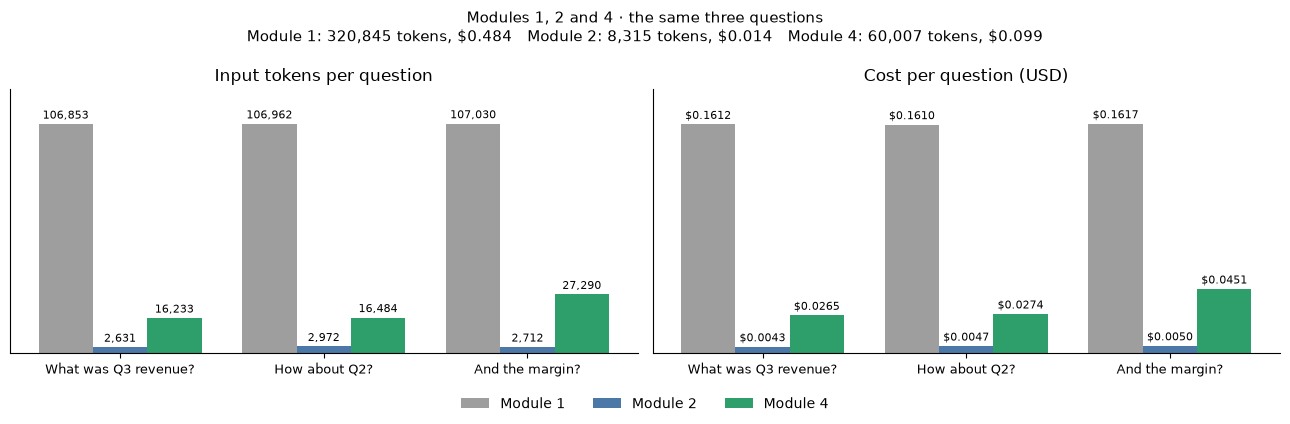

In [25]:
conversation = runs[-3:] # the three questions above
save_runs("module_4", conversation)
earlier = {m: r for m, r in [("Module 1", load_runs("module_1")), ("Module 2", load_runs("module_2"))] if r}
if len(earlier) < 2:
    print("Run Modules 1 and 2 first to chart against them.")
compare(earlier | {"Module 4": conversation}, "Modules 1, 2 and 4 · the same three questions")

## Checkpoint · Module 4 gets it right, in a notebook

| ✓ What Module 4 can do | ✗ What still breaks |
|---|---|
| Routes: no search for small talk | No API for real users → Ch 5 |
| Grades chunks, rewrites and retries, capped | A restart loses the conversation → Ch 5 |
| Answers only from the evidence | Can't see cost per step → Ch 5 |
| Says so when it can't find a fact | Vector search misses exact wording (Q2 revenue) → hybrid search |
| | No human approval for risky actions → Ch 5 |

Module 5 serves this same graph with AgentShip:

```bash
agentship run agents/agentic_rag.yaml --input "How did Acme's Q3 margin compare to Q2, and why?"
agentship serve --agents-dir agents
```